In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

In [8]:

url = (
    "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
)

df = pd.read_csv(url, sep="\t", header=None,
                 names=["label", "message"])

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass distribution:")
print(df["label"].value_counts())


Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [5]:

model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 96.05%

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



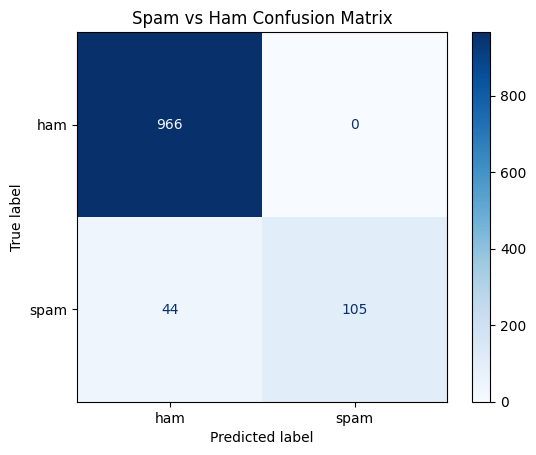

In [6]:

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["ham", "spam"],
    cmap="Blues"
)
plt.title("Spam vs Ham Confusion Matrix")
plt.show()

In [7]:

messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! Claim your cash reward immediately."
]

predictions = model.predict(messages)

for message, prediction in zip(messages, predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()}\n")

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM

Message: Hey, are we meeting for lunch today?
Prediction: HAM

Message: URGENT! Claim your cash reward immediately.
Prediction: SPAM

